# Seattle buildings: energy use and emissions
Day 1 assignment, data cleaning + EDA

Chloe Hraibeh, Jeff El Khoury, Luca Obejdeanu
AI Methods I, IAAC MaAI 2026/27

### Question
What makes some buildings use more energy and emit more CO2 than others? We look at use, age, height and type of energy.

Data: Seattle building energy report 2016 (3,376 buildings). The clean table can be used later for a model.

# 0. Setup and data

## 0.1 Libraries

In [1]:
#import all required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub as kh
from kagglehub import KaggleDatasetAdapter
from pathlib import Path

/opt/anaconda3/envs/ai-methods/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#folders (one level up from the notebook)
DATA_DIR = Path("..") / "data"
FIG_DIR = Path("..") / "figures"
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

#display options
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

#plot style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

#seed for anything random
RANDOM_STATE = 42

## 0.2 Getting the data
The dataset is public on Kaggle (it was uploaded by the City of Seattle) so we just load it with kagglehub. We only use data from 2016(the database is for 2015 and 2016).

In [3]:
#load the 2016 file from kaggle
df = kh.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "city-of-seattle/sea-building-energy-benchmarking",
    "2016-building-energy-benchmarking.csv",
)

print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns")

Loaded 3,376 rows and 46 columns


In [4]:
#save a copy of the raw data
raw_path = DATA_DIR / "seattle_2016_raw.csv"
df.to_csv(raw_path, index=False)
print(f"Raw data saved to {raw_path}")

Raw data saved to ../data/seattle_2016_raw.csv


## 0.3 Dataset card

| | |
|---|---|
| Name | 2016 Building Energy Benchmarking (Seattle) |
| Source | Kaggle, [city-of-seattle/sea-building-energy-benchmarking](https://www.kaggle.com/datasets/city-of-seattle/sea-building-energy-benchmarking) |
| Origin | yearly energy reports of buildings over 20,000 sqft (~1,860 m2) |
| One row | one building |
| Size | 3,376 rows, 46 columns |
| Licence | Public Domain |
| Limitations | only big buildings, self reported, one city, one year, US units |

## 0.4 First look

In [5]:
#first 5 rows
df.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,"98,101.00",0659000030,7,DOWNTOWN,47.61,-122.34,1927,1.00,12,88434,0,88434,Hotel,Hotel,"88,434.00",NaN,NaN,NaN,NaN,NaN,60.00,81.70,84.30,182.50,189.00,"7,226,362.50","7,456,910.00","2,003,882.00","1,156,514.25","3,946,027.00","12,764.53","1,276,453.00",False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,"98,101.00",0659000220,7,DOWNTOWN,47.61,-122.33,1996,1.00,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,"83,880.00",Parking,"15,064.00",Restaurant,"4,622.00",NaN,61.00,94.80,97.90,176.10,179.40,"8,387,933.00","8,664,479.00",0.00,"950,425.19","3,242,851.00","51,450.82","5,145,082.00",False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,"98,101.00",0659000475,7,DOWNTOWN,47.61,-122.34,1969,1.00,41,956110,196718,759392,Hotel,Hotel,"756,493.00",NaN,NaN,NaN,NaN,NaN,43.00,96.00,97.70,241.90,244.10,"72,587,024.00","73,937,112.00","21,566,554.00","14,515,435.00","49,526,664.00","14,938.00","1,493,800.00",False,NaN,Compliant,NaN,"2,089.28",2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,"98,101.00",0659000640,7,DOWNTOWN,47.61,-122.34,1926,1.00,10,61320,0,61320,Hotel,Hotel,"61,320.00",NaN,NaN,NaN,NaN,NaN,56.00,110.80,113.30,216.20,224.00,"6,794,584.00","6,946,800.50","2,214,446.25","811,525.31","2,768,924.00","18,112.13","1,811,213.00",False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,"98,121.00",0659000970,7,DOWNTOWN,47.61,-122.34,1980,1.00,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,"123,445.00",Parking,"68,009.00",Swimming Pool,0.00,NaN,75.00,114.80,118.70,211.40,215.60,"14,172,606.00","14,656,503.00",0.00,"1,573,448.62","5,368,607.00","88,039.98","8,803,998.00",False,NaN,Compliant,NaN,505.01,2.88


In [6]:
#info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    3376 non-null   int64  
 1   DataYear                         3376 non-null   int64  
 2   BuildingType                     3376 non-null   str    
 3   PrimaryPropertyType              3376 non-null   str    
 4   PropertyName                     3376 non-null   str    
 5   Address                          3376 non-null   str    
 6   City                             3376 non-null   str    
 7   State                            3376 non-null   str    
 8   ZipCode                          3360 non-null   float64
 9   TaxParcelIdentificationNumber    3376 non-null   str    
 10  CouncilDistrictCode              3376 non-null   int64  
 11  Neighborhood                     3376 non-null   str    
 12  Latitude                       

In [7]:
#summary of all columns
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
OSEBuildingID,"3,376.00",NaN,NaN,NaN,"21,208.99","12,223.76",1.00,"19,990.75","23,112.00","25,994.25","50,226.00"
DataYear,"3,376.00",NaN,NaN,NaN,"2,016.00",0.00,"2,016.00","2,016.00","2,016.00","2,016.00","2,016.00"
BuildingType,3376,8,NonResidential,1460,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PrimaryPropertyType,3376,24,Low-Rise Multifamily,987,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PropertyName,3376,3362,Northgate Plaza,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Address,3376,3354,2600 SW Barton St,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,3376,1,Seattle,3376,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,3376,1,WA,3376,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ZipCode,"3,360.00",NaN,NaN,NaN,"98,116.95",18.62,"98,006.00","98,105.00","98,115.00","98,122.00","98,272.00"
TaxParcelIdentificationNumber,3376,3268,1625049001,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN


How to read this table:
- count: how many values are not missing (less than 3,376 = missing values)
- unique / top / freq: only for **text** columns. Number of different values, the most common one and how many times it shows up
- mean / std / min / max: only for **numbers**. Average, how spread out the values are, smallest and biggest
- 25% / 50% / 75%: half of the buildings are between 25% and 75%, 50% is the median

Already some weird stuff here: City and State have only 1 value, 0 and 99 floors, energy use of 0 and negative values. We fix this in the cleaning.

### Main columns

| Column | Meaning |
|---|---|
| `BuildingType` | nonresidential, multifamily low-rise (1-4 floors), mid-rise (5-9), high-rise (10+)... |
| `PrimaryPropertyType` | main use (office, hotel, warehouse...) |
| `Neighborhood`, `Latitude`, `Longitude` | location |
| `YearBuilt`, `NumberofFloors` | year built, floors |
| `PropertyGFATotal` | floor area in sqft (buildings + parking) |
| `ENERGYSTARScore` | EPA score 1-100, 50 = US average |
| `SiteEUI(kBtu/sf)` | energy per sqft per year, our main variable |
| `SiteEnergyUse(kBtu)` | total energy per year |
| `Electricity`, `NaturalGas`, `SteamUse` | energy by source |
| `TotalGHGEmissions`, `GHGEmissionsIntensity` | emissions (total and per sqft) |
| `ComplianceStatus`, `Outlier` | city data checks |

# 1. Data cleaning

In [8]:
#make a clean copy of the original table
df_clean = df.copy()

We make a copy of `df` and do all the cleaning on `df_clean`, so the original data stays untouched. This way we can compare before vs after at the end, and if we mess something up we can just start again from `df`. (Without `.copy()` both names would point to the same table, so changing one would change the other too.)

## 1.1 Column names

In [9]:
#give new names to columns
new_names = {
    "OSEBuildingID": "building_id",
    "DataYear": "data_year",
    "BuildingType": "building_type",
    "PrimaryPropertyType": "primary_property_type",
    "PropertyName": "property_name",
    "Address": "address",
    "City": "city",
    "State": "state",
    "ZipCode": "zip_code",
    "TaxParcelIdentificationNumber": "tax_parcel_id",
    "CouncilDistrictCode": "council_district",
    "Neighborhood": "neighborhood",
    "Latitude": "latitude",
    "Longitude": "longitude",
    "YearBuilt": "year_built",
    "NumberofBuildings": "number_of_buildings",
    "NumberofFloors": "number_of_floors",
    "PropertyGFATotal": "gfa_total",
    "PropertyGFAParking": "gfa_parking",
    "PropertyGFABuilding(s)": "gfa_buildings",
    "ListOfAllPropertyUseTypes": "all_use_types",
    "LargestPropertyUseType": "largest_use_type",
    "LargestPropertyUseTypeGFA": "largest_use_type_gfa",
    "SecondLargestPropertyUseType": "second_use_type",
    "SecondLargestPropertyUseTypeGFA": "second_use_type_gfa",
    "ThirdLargestPropertyUseType": "third_use_type",
    "ThirdLargestPropertyUseTypeGFA": "third_use_type_gfa",
    "YearsENERGYSTARCertified": "years_energystar_certified",
    "ENERGYSTARScore": "energystar_score",
    "SiteEUI(kBtu/sf)": "site_eui",
    "SiteEUIWN(kBtu/sf)": "site_eui_wn",
    "SourceEUI(kBtu/sf)": "source_eui",
    "SourceEUIWN(kBtu/sf)": "source_eui_wn",
    "SiteEnergyUse(kBtu)": "site_energy_use",
    "SiteEnergyUseWN(kBtu)": "site_energy_use_wn",
    "SteamUse(kBtu)": "steam_use",
    "Electricity(kWh)": "electricity_kwh",
    "Electricity(kBtu)": "electricity",
    "NaturalGas(therms)": "natural_gas_therms",
    "NaturalGas(kBtu)": "natural_gas",
    "DefaultData": "default_data",
    "Comments": "comments",
    "ComplianceStatus": "compliance_status",
    "Outlier": "outlier",
    "TotalGHGEmissions": "total_ghg",
    "GHGEmissionsIntensity": "ghg_intensity",
}

df_clean = df_clean.rename(columns=new_names)
df_clean.columns.tolist()

['building_id',
 'data_year',
 'building_type',
 'primary_property_type',
 'property_name',
 'address',
 'city',
 'state',
 'zip_code',
 'tax_parcel_id',
 'council_district',
 'neighborhood',
 'latitude',
 'longitude',
 'year_built',
 'number_of_buildings',
 'number_of_floors',
 'gfa_total',
 'gfa_parking',
 'gfa_buildings',
 'all_use_types',
 'largest_use_type',
 'largest_use_type_gfa',
 'second_use_type',
 'second_use_type_gfa',
 'third_use_type',
 'third_use_type_gfa',
 'years_energystar_certified',
 'energystar_score',
 'site_eui',
 'site_eui_wn',
 'source_eui',
 'source_eui_wn',
 'site_energy_use',
 'site_energy_use_wn',
 'steam_use',
 'electricity_kwh',
 'electricity',
 'natural_gas_therms',
 'natural_gas',
 'default_data',
 'comments',
 'compliance_status',
 'outlier',
 'total_ghg',
 'ghg_intensity']

The original names have brackets, units and random capitals (like `SiteEUI(kBtu/sf)`), so they're annoying to type and easy to get wrong. 

## 1.2 Duplicates

In [10]:
#check for duplicate rows and duplicate building ids
n_duplicates = df_clean.duplicated().sum()
n_duplicate_ids = df_clean["building_id"].duplicated().sum()

print(f"Duplicate rows: {n_duplicates}")
print(f"Duplicate building ids: {n_duplicate_ids}")

Duplicate rows: 0
Duplicate building ids: 0


`duplicated()` gives True for every row that is an exact copy of a row above, `.sum()` counts them. We also check `building_id` alone, in case the same building shows up twice with different values. Both are 0.

No duplicates.

## 1.3 Missing values

In [11]:
#number and percentage of missing values per column
def missing_report(data):
    n_missing = data.isnull().sum()
    pct_missing = (n_missing / len(data)) * 100
    report = pd.DataFrame({
        "n_missing": n_missing,
        "pct_missing": pct_missing
    })
    return report.sort_values("pct_missing", ascending=False)

missing = missing_report(df_clean)
missing[missing["n_missing"] > 0]

,n_missing,pct_missing
comments,3376,100.00
outlier,3344,99.05
years_energystar_certified,3257,96.48
third_use_type,2780,82.35
third_use_type_gfa,2780,82.35
second_use_type,1697,50.27
second_use_type_gfa,1697,50.27
energystar_score,843,24.97
largest_use_type_gfa,20,0.59
largest_use_type,20,0.59


We made a small function so we can reuse it later. It counts the missing values (NaN) in every column and turns them into a % of all rows, sorted from most to least missing. We only show the columns that actually have missing values.

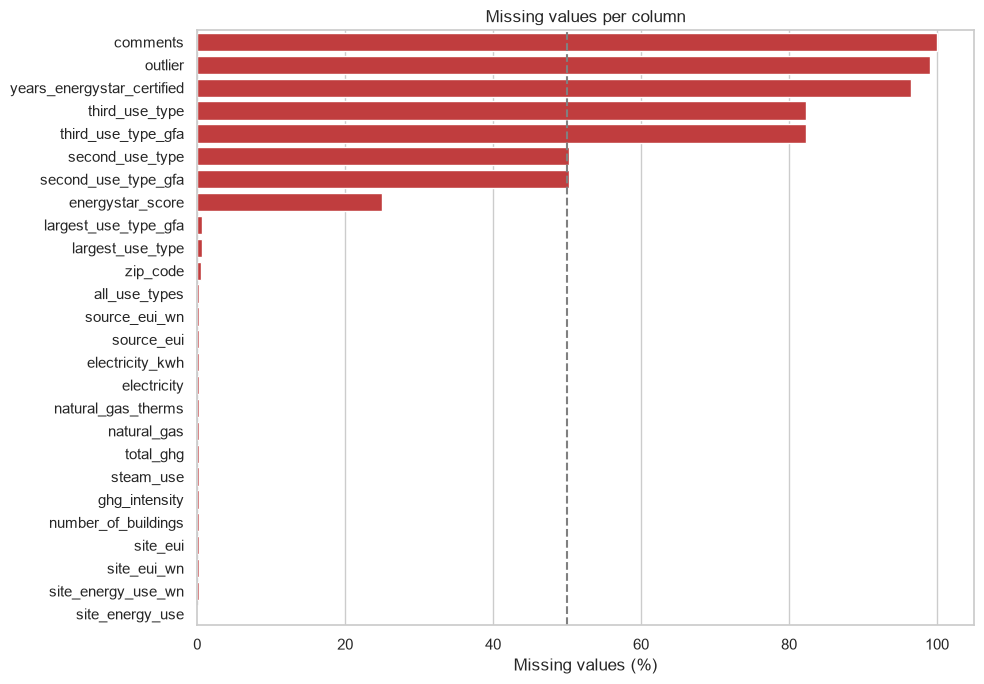

In [12]:
#bar chart of the columns with missing values
missing_to_plot = missing[missing["pct_missing"] > 0]

fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(data=missing_to_plot, x="pct_missing", y=missing_to_plot.index, color="tab:red", ax=ax)
ax.axvline(50, color="grey", linestyle="--")
ax.set_title("Missing values per column")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_missing_values.png", dpi=150, bbox_inches="tight")
plt.show()

- `comments` is empty, `outlier` and `years_energystar_certified` almost (99%, 96%)
- second and third use are missing for 50% and 82%, most buildings just have one use
- `energystar_score` missing for 25%, see 1.10
- energy columns are almost complete

## 1.4 Dropping columns

| Column | Why |
|---|---|
| `comments`, `years_energystar_certified` | (almost) empty |
| `data_year`, `city`, `state` | always the same |
| `address`, `zip_code`, `tax_parcel_id`, `council_district` | we have neighborhood and lat/long |
| use type columns (all, largest, second, third) | we use `primary_property_type` |
| `..._wn` columns, `source_eui` | other versions of the same values |
| `electricity_kwh`, `natural_gas_therms` | same values in another unit |
| `default_data` | already covered by `compliance_status` |

In [13]:
#column removal
columns_to_drop = [
    "comments",
    "years_energystar_certified",
    "data_year",
    "city",
    "state",
    "address",
    "zip_code",
    "tax_parcel_id",
    "council_district",
    "all_use_types",
    "largest_use_type",
    "largest_use_type_gfa",
    "second_use_type",
    "second_use_type_gfa",
    "third_use_type",
    "third_use_type_gfa",
    "site_eui_wn",
    "source_eui_wn",
    "site_energy_use_wn",
    "source_eui",
    "electricity_kwh",
    "natural_gas_therms",
    "default_data",
]

df_clean = df_clean.drop(columns=columns_to_drop)
print(f"Remaining columns ({df_clean.shape[1]}): {df_clean.columns.tolist()}")

Remaining columns (23): ['building_id', 'building_type', 'primary_property_type', 'property_name', 'neighborhood', 'latitude', 'longitude', 'year_built', 'number_of_buildings', 'number_of_floors', 'gfa_total', 'gfa_parking', 'gfa_buildings', 'energystar_score', 'site_eui', 'site_energy_use', 'steam_use', 'electricity', 'natural_gas', 'compliance_status', 'outlier', 'total_ghg', 'ghg_intensity']


`drop(columns=...)` removes the columns in the list. We only keep what helps with our question, the rest was empty, always the same, or a copy of another column.

## 1.5 Buildings the city doesn't trust

In [14]:
#compliance status and outlier flag
print(df_clean["compliance_status"].value_counts(dropna=False))
print()
pd.crosstab(df_clean["compliance_status"], df_clean["outlier"].fillna("not flagged"))

compliance_status
Compliant                       3211
Error - Correct Default Data     113
Non-Compliant                     37
Missing Data                      15
Name: count, dtype: int64



outlier,High outlier,Low outlier,not flagged
compliance_status,,,
Compliant,0,0,3211
Error - Correct Default Data,0,2,111
Missing Data,0,0,15
Non-Compliant,9,21,7


165 buildings are not ***"Compliant"*** (default data, missing data or not following the rules), including all 32 outliers. We remove them (5%).

In [15]:
#keep only the compliant buildings
rows_before = len(df_clean)
df_clean = df_clean[df_clean["compliance_status"] == "Compliant"].copy()
df_clean = df_clean.reset_index(drop=True)

print(f"Removed {rows_before - len(df_clean)} buildings, {len(df_clean):,} left")
print(f"Outliers left: {df_clean['outlier'].notna().sum()}")

#drop the flag columns
df_clean = df_clean.drop(columns=["compliance_status", "outlier"])

Removed 165 buildings, 3,211 left
Outliers left: 0


## 1.6 Categories written in different ways

In [16]:
#neighborhood names
df_clean["neighborhood"].value_counts().sort_index()

neighborhood
BALLARD                   120
Ballard                     6
CENTRAL                    95
Central                    26
DELRIDGE                   73
DELRIDGE NEIGHBORHOODS      1
DOWNTOWN                  556
Delridge                    4
EAST                      440
GREATER DUWAMISH          357
LAKE UNION                244
MAGNOLIA / QUEEN ANNE     412
NORTH                     136
NORTHEAST                 266
NORTHWEST                 198
North                      40
Northwest                  10
SOUTHEAST                  78
SOUTHWEST                 149
Name: count, dtype: int64

Same neighborhoods written differently (`BALLARD`/`Ballard`, Delridge 3 times). We put everything in capitals.

In [17]:
#all in capitals + merge delridge
df_clean["neighborhood"] = df_clean["neighborhood"].str.upper()
df_clean["neighborhood"] = df_clean["neighborhood"].replace("DELRIDGE NEIGHBORHOODS", "DELRIDGE")

df_clean["neighborhood"].value_counts()

neighborhood
DOWNTOWN                 556
EAST                     440
MAGNOLIA / QUEEN ANNE    412
GREATER DUWAMISH         357
NORTHEAST                266
LAKE UNION               244
NORTHWEST                208
NORTH                    176
SOUTHWEST                149
BALLARD                  126
CENTRAL                  121
SOUTHEAST                 78
DELRIDGE                  78
Name: count, dtype: int64

In [18]:
#building type
df_clean["building_type"].value_counts()

building_type
NonResidential          1432
Multifamily LR (1-4)     985
Multifamily MR (5-9)     570
Multifamily HR (10+)     108
Nonresidential COS        81
Campus                    24
SPS-District K-12         10
Nonresidential WA          1
Name: count, dtype: int64

*"NonResidential"* and *"Nonresidential"* are the same thing written twice. *"COS"* means owned by the City of Seattle and *"WA"* owned by Washington State. Who owns the building doesn't matter for us, so we put them all under **"Nonresidential"**.

In [19]:
#same spelling for all the nonresidential types
df_clean["building_type"] = df_clean["building_type"].replace({
    "NonResidential": "Nonresidential",
    "Nonresidential COS": "Nonresidential",
    "Nonresidential WA": "Nonresidential",
})

df_clean["building_type"].value_counts()

building_type
Nonresidential          1514
Multifamily LR (1-4)     985
Multifamily MR (5-9)     570
Multifamily HR (10+)     108
Campus                    24
SPS-District K-12         10
Name: count, dtype: int64

## 1.7 Values that can't be right

In [20]:
#buildings with 0 floors, 0 buildings or more than 50 floors
print(f"0 floors: {(df_clean['number_of_floors'] == 0).sum()}")
print(f"0 buildings: {(df_clean['number_of_buildings'] == 0).sum()}")
print()
df_clean[df_clean["number_of_floors"] > 50][["property_name", "primary_property_type", "number_of_floors", "gfa_total"]]

0 floors: 16
0 buildings: 91



,property_name,primary_property_type,number_of_floors,gfa_total
189,Seattle Municipal Tower (2030),Large Office,63,1354987
227,1201 Third Avenue,Large Office,55,1400000
247,Two Union Square,Large Office,56,1605578
509,Columbia Center - 2015,Large Office,76,1952220
1271,Seattle Chinese Baptist Church,Worship Facility,99,21948


16 big buildings with 0 floors, 91 with 0 buildings and a church with 99 floors on ~2,000 m2. These are errors, we set them to NaN. The 4 towers over 50 floors are real.

In [21]:
#impossible values -> NaN
df_clean["number_of_floors"] = df_clean["number_of_floors"].replace(0, np.nan)
df_clean.loc[df_clean["number_of_floors"] == 99, "number_of_floors"] = np.nan
df_clean["number_of_buildings"] = df_clean["number_of_buildings"].replace(0, np.nan)

print(f"Missing floors now: {df_clean['number_of_floors'].isna().sum()}")

Missing floors now: 17


In [22]:
#negative energy or emissions
energy_columns = ["site_eui", "site_energy_use", "electricity", "natural_gas", "steam_use", "total_ghg"]
negative = (df_clean[energy_columns] < 0).any(axis=1)

df_clean[negative][["property_name", "primary_property_type"] + energy_columns]

,property_name,primary_property_type,site_eui,site_energy_use,electricity,natural_gas,steam_use,total_ghg
3046,Bullitt Center,Small- and Mid-Sized Office,7.10,"342,726.09","-115,417.00",0.00,0.00,-0.80


The only negative one is the Bullitt Center, it has solar panels and produces more electricity than it uses. Not an error, we keep it.

## 1.8 New columns
- metric units: m2, kWh/m2, kg CO2/m2
- `gas_share`: part of the energy from gas
- `building_age`
- `gfa_per_floor_m2`: area / floors
- `parking_share`: part of the area that is parking
- `use_group`: multifamily / office / other

In [23]:
#metric units
df_clean["gfa_m2"] = df_clean["gfa_buildings"] / 10.7639
df_clean["site_eui_kwh_m2"] = df_clean["site_eui"] * 3.1546
df_clean["ghg_kg_m2"] = df_clean["ghg_intensity"] * 10.7639

#share of natural gas in the total energy
df_clean["gas_share"] = df_clean["natural_gas"] / df_clean["site_energy_use"]

#age, footprint and parking
df_clean["building_age"] = 2016 - df_clean["year_built"]
df_clean["gfa_per_floor_m2"] = df_clean["gfa_m2"] / df_clean["number_of_floors"]
df_clean["parking_share"] = df_clean["gfa_parking"] / df_clean["gfa_total"]

#3 use groups
df_clean["use_group"] = "Other"
df_clean.loc[df_clean["building_type"].str.startswith("Multifamily"), "use_group"] = "Multifamily"
df_clean.loc[df_clean["primary_property_type"].isin(["Large Office", "Small- and Mid-Sized Office"]), "use_group"] = "Office"

new_columns = ["gfa_m2", "site_eui_kwh_m2", "ghg_kg_m2", "gas_share", "building_age", "gfa_per_floor_m2", "parking_share"]
df_clean[new_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
gfa_m2,"3,211.00","8,122.63","19,654.52",337.80,"2,560.74","3,977.74","7,850.18","865,871.66"
site_eui_kwh_m2,"3,211.00",175.47,178.94,4.42,88.64,123.98,194.01,"2,632.20"
ghg_kg_m2,"3,207.00",12.80,19.85,-0.22,2.26,6.57,14.85,366.94
gas_share,"3,207.00",0.25,0.27,0.00,0.00,0.18,0.45,1.00
building_age,"3,211.00",47.26,33.16,1.00,19.00,41.00,68.00,116.00
gfa_per_floor_m2,"3,194.00","2,023.90","3,293.67",168.90,768.60,"1,201.79","2,207.45","102,193.44"
parking_share,"3,211.00",0.04,0.12,0.00,0.00,0.00,0.00,0.90


In [24]:
#check: energy / area = eui
check = (df_clean["site_energy_use"] / df_clean["gfa_buildings"]) / df_clean["site_eui"]
print(f"Median ratio: {check.median():.3f}")
print(df_clean["use_group"].value_counts())

Median ratio: 1.000
use_group
Multifamily    1662
Other          1093
Office          456
Name: count, dtype: int64


Ratio = 1, so the energy intensity uses the area without parking.

## 1.9 Outliers

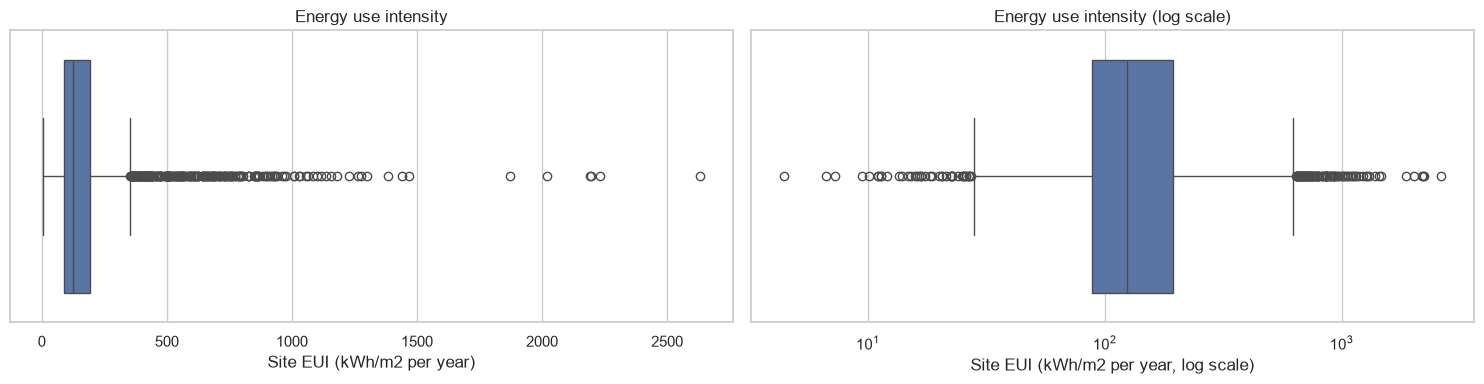

In [25]:
#boxplot of the energy intensity, normal scale and log scale
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

sns.boxplot(x=df_clean["site_eui_kwh_m2"], ax=axes[0])
axes[0].set_title("Energy use intensity")
axes[0].set_xlabel("Site EUI (kWh/m2 per year)")

sns.boxplot(x=df_clean["site_eui_kwh_m2"], log_scale=True, ax=axes[1])
axes[1].set_title("Energy use intensity (log scale)")
axes[1].set_xlabel("Site EUI (kWh/m2 per year, log scale)")

plt.tight_layout()
plt.savefig(FIG_DIR / "02_eui_outliers.png", dpi=150, bbox_inches="tight")
plt.show()

In [26]:
#IQR rule and percentile rule
eui = df_clean["site_eui_kwh_m2"]

q1, q3 = eui.quantile([0.25, 0.75])
iqr = q3 - q1
iqr_outliers = (eui < q1 - 1.5 * iqr) | (eui > q3 + 1.5 * iqr)

p01, p99 = eui.quantile([0.01, 0.99])
pct_outliers = (eui < p01) | (eui > p99)

print(f"IQR rule: {iqr_outliers.sum()} buildings (above {q3 + 1.5 * iqr:.0f} kWh/m2)")
print(f"Percentile rule: {pct_outliers.sum()} buildings (below {p01:.0f} or above {p99:.0f} kWh/m2)")

IQR rule: 244 buildings (above 352 kWh/m2)
Percentile rule: 66 buildings (below 25 or above 921 kWh/m2)


In [27]:
#which buildings does the IQR rule flag
df_clean[iqr_outliers]["primary_property_type"].value_counts().head(8)

primary_property_type
Other                          70
Supermarket / Grocery Store    35
Mixed Use Property             28
Small- and Mid-Sized Office    20
Large Office                   13
Hotel                          11
Retail Store                   11
Hospital                        9
Name: count, dtype: int64

In [28]:
#the 6 highest and the 6 lowest
columns_to_show = ["property_name", "primary_property_type", "site_eui_kwh_m2"]
print(df_clean.nlargest(6, "site_eui_kwh_m2")[columns_to_show])
print()
print(df_clean.nsmallest(6, "site_eui_kwh_m2")[columns_to_show])

                         property_name primary_property_type  site_eui_kwh_m2
196               UW Tower Data Center                 Other         2,632.20
263       Fisher Plaza - West Building    Mixed Use Property         2,231.25
745                  3000/3018 Western            Laboratory         2,197.81
3043      2020 Fifth Avenue Dat Center                 Other         2,191.50
508                     WestinBuilding                 Other         2,018.00
3011  Seattle ProCure Management, LLC.                 Other         1,872.57

                       property_name  primary_property_type  site_eui_kwh_m2
1483            A1 Self Storage, LLC  Self-Storage Facility             4.42
544            Westcore River Street    Distribution Center             6.62
2128  3420/3430 E. Marginal Way Whse    Distribution Center             7.26
901                  Meaves Building              Warehouse             9.46
1482               Mahoney Warehouse  Self-Storage Facility         

Two ways to find outliers: the IQR rule (way above or below the box of the boxplot) flags 244 buildings, the 1%-99% rule only 66. Before deleting anything we check which buildings they are: mostly supermarkets, hospitals, hotels and data centers, which really use a lot of energy. So they're real, not mistakes, and we keep them.

We use the same two rules as in class (IQR and 1%-99%). The difference: in class the extreme values were mistakes, so they got removed. Here the city already took out its own outliers in 1.5, and what's left are real buildings that just use a lot of energy, so we keep them.

## 1.10 Remaining missing values

In [29]:
#missing values after cleaning
missing_report(df_clean).head(6)

,n_missing,pct_missing
energystar_score,812,25.29
number_of_buildings,94,2.93
gfa_per_floor_m2,17,0.53
number_of_floors,17,0.53
steam_use,4,0.12
gas_share,4,0.12


In [30]:
#% missing energy star per type
energystar_missing = df_clean.groupby("primary_property_type")["energystar_score"].apply(lambda s: s.isna().mean() * 100)
energystar_missing.sort_values(ascending=False).head(10)

primary_property_type
University               100.00
Self-Storage Facility    100.00
Restaurant               100.00
Laboratory               100.00
Other                     95.60
Mixed Use Property        72.73
Refrigerated Warehouse    58.33
Distribution Center       24.53
Warehouse                 23.78
Mid-Rise Multifamily      18.44
Name: energystar_score, dtype: float64

After cleaning, most missing values are the ones we set to NaN ourselves (floors, buildings). ENERGY STAR is the big one (25%). Grouping by type shows it's not random: universities, labs, restaurants and storage never have a score because the EPA doesn't give them one. So filling it with the median would be making up scores, we leave it as NaN.

## 1.11 Final check and save

In [31]:
#final columns
final_columns = [
    #id and location
    "building_id", "neighborhood", "latitude", "longitude",
    #type and use
    "building_type", "primary_property_type", "use_group",
    #size and shape
    "year_built", "building_age", "number_of_buildings", "number_of_floors",
    "gfa_m2", "gfa_per_floor_m2", "parking_share",
    #energy (target for modelling)
    "site_eui_kwh_m2", "energystar_score", "gas_share",
    #emissions
    "ghg_kg_m2", "total_ghg",
    #metered energy (leakage if we model)
    "site_energy_use", "electricity", "natural_gas", "steam_use",
]

df_clean = df_clean[final_columns]
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 3211 entries, 0 to 3210
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   building_id            3211 non-null   int64  
 1   neighborhood           3211 non-null   str    
 2   latitude               3211 non-null   float64
 3   longitude              3211 non-null   float64
 4   building_type          3211 non-null   str    
 5   primary_property_type  3211 non-null   str    
 6   use_group              3211 non-null   str    
 7   year_built             3211 non-null   int64  
 8   building_age           3211 non-null   int64  
 9   number_of_buildings    3117 non-null   float64
 10  number_of_floors       3194 non-null   float64
 11  gfa_m2                 3211 non-null   float64
 12  gfa_per_floor_m2       3194 non-null   float64
 13  parking_share          3211 non-null   float64
 14  site_eui_kwh_m2        3211 non-null   float64
 15  energystar_scor

We pick the columns based on our question: the energy and emissions per m2 (what we want to explain), and the things we think affect them (use, age, height, size, gas, location). We drop the ones we only needed during cleaning (like the building names) and the sqft / kBtu versions, since we now have m2 and kWh.

In [32]:
#comparing the raw and the clean table
comparison = pd.DataFrame(
    {
        "raw": [
            len(df),
            df.shape[1],
            df.select_dtypes("number").shape[1],
            df.isna().mean().mean() * 100,
        ],
        "clean": [
            len(df_clean),
            df_clean.shape[1],
            df_clean.select_dtypes("number").shape[1],
            df_clean.isna().mean().mean() * 100,
        ],
    },
    index=["rows", "columns", "numeric columns", "average % missing"],
)
comparison

,raw,clean
rows,"3,376.00","3,211.00"
columns,46.00,23.00
numeric columns,30.00,19.00
average % missing,12.85,1.31


In [33]:
#save the cleaned table in data/
clean_path = DATA_DIR / "seattle_buildings_clean.csv"
df_clean.to_csv(clean_path, index=False)
print(f"Cleaned table saved to {clean_path} ({clean_path.stat().st_size / 1e6:.2f} MB)")

Cleaned table saved to ../data/seattle_buildings_clean.csv (0.72 MB)


# 2. **EDA**

**EDA** = looking at the data from every angle (stats + plots) to understand it before building any model. We use it to answer our question and to see which variables actually matter.

Main variables: `site_eui_kwh_m2` (energy per m2 per year) and `ghg_kg_m2` (emissions per m2 per year).

## 2.1 Basic stats

In [34]:
#main numeric columns
eda_columns = ["site_eui_kwh_m2", "ghg_kg_m2", "energystar_score", "year_built", "number_of_floors", "gfa_m2", "gas_share"]

stats = df_clean[eda_columns].describe().T
stats["skewness"] = df_clean[eda_columns].skew()
stats

,count,mean,std,min,25%,50%,75%,max,skewness
site_eui_kwh_m2,"3,211.00",175.47,178.94,4.42,88.64,123.98,194.01,"2,632.20",5.00
ghg_kg_m2,"3,207.00",12.80,19.85,-0.22,2.26,6.57,14.85,366.94,5.57
energystar_score,"2,399.00",67.25,26.96,1.00,52.00,74.00,89.00,100.00,-0.82
year_built,"3,211.00","1,968.74",33.16,"1,900.00","1,948.00","1,975.00","1,997.00","2,015.00",-0.54
number_of_floors,"3,194.00",4.80,5.34,1.00,2.00,4.00,5.00,76.00,5.03
gfa_m2,"3,211.00","8,122.63","19,654.52",337.80,"2,560.74","3,977.74","7,850.18","865,871.66",27.50
gas_share,"3,207.00",0.25,0.27,0.00,0.00,0.18,0.45,1.00,0.69


In [35]:
df_clean["site_eui_kwh_m2"].median()

np.float64(123.97577760250398)

Skewness: 0 means symmetric, above 1 means a few very big values pull everything to the right. Energy (5) and area (27) are really skewed, that's why we look at medians and log scales.

- median 124 kWh/m2, mean 175: a few buildings pull the mean up, so we use the median
- emissions median 6.6 kg CO2e/m2
- median ENERGY STAR 74 (US average is 50)
- half of the buildings are from before 1975 and have 4 floors or less

## 2.2 Distributions

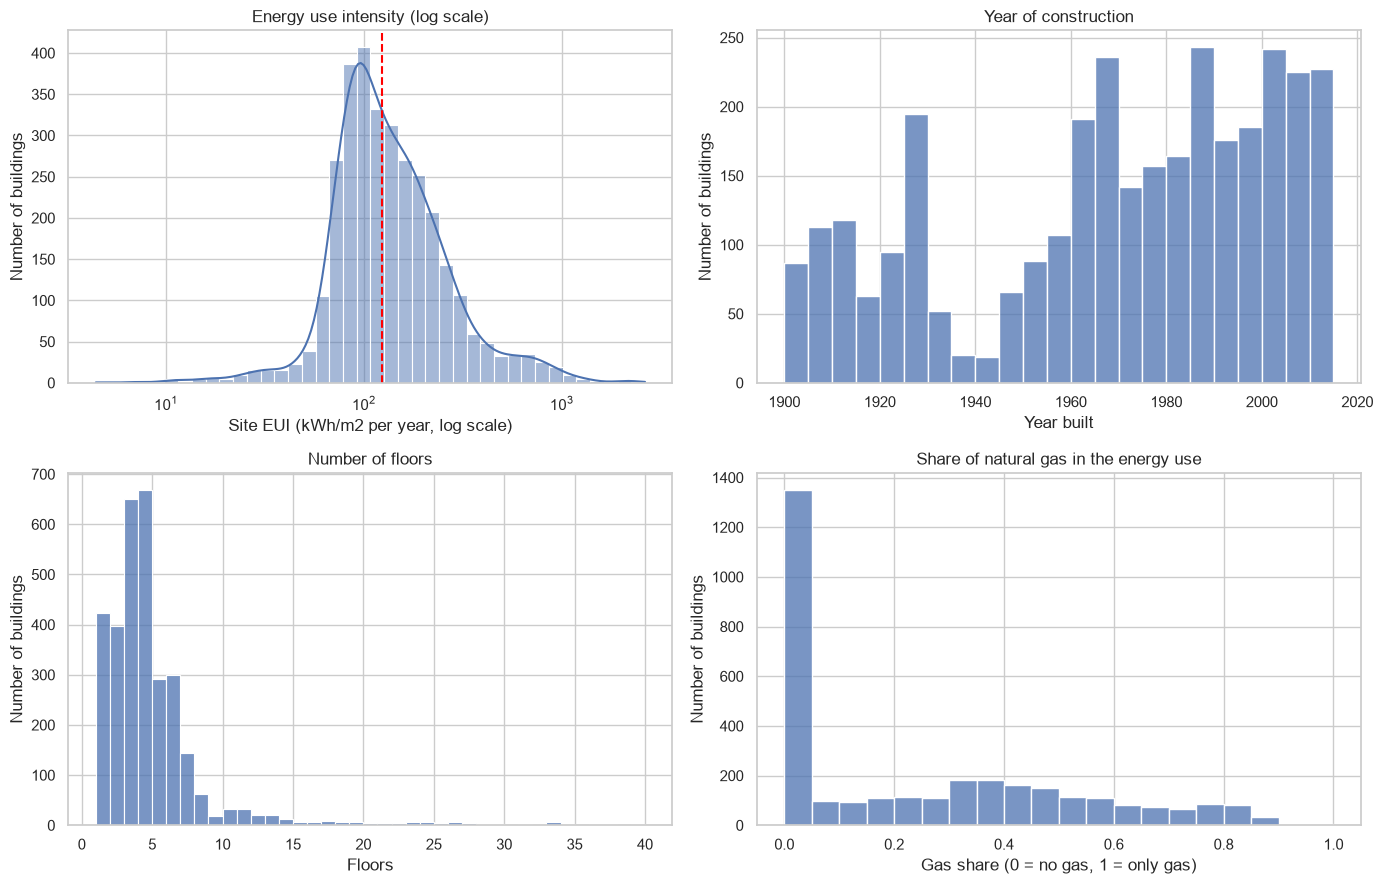

In [36]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(df_clean["site_eui_kwh_m2"], bins=40, log_scale=True, kde=True, ax=axes[0, 0])
axes[0, 0].axvline(df_clean["site_eui_kwh_m2"].median(), color="red", linestyle="--")
axes[0, 0].set_title("Energy use intensity (log scale)")
axes[0, 0].set_xlabel("Site EUI (kWh/m2 per year, log scale)")
axes[0, 0].set_ylabel("Number of buildings")

sns.histplot(df_clean["year_built"], bins=23, ax=axes[0, 1])
axes[0, 1].set_title("Year of construction")
axes[0, 1].set_xlabel("Year built")
axes[0, 1].set_ylabel("Number of buildings")

sns.histplot(df_clean["number_of_floors"], bins=range(1, 41), ax=axes[1, 0])
axes[1, 0].set_title("Number of floors")
axes[1, 0].set_xlabel("Floors")
axes[1, 0].set_ylabel("Number of buildings")

sns.histplot(df_clean["gas_share"], bins=20, ax=axes[1, 1])
axes[1, 1].set_title("Share of natural gas in the energy use")
axes[1, 1].set_xlabel("Gas share (0 = no gas, 1 = only gas)")
axes[1, 1].set_ylabel("Number of buildings")

plt.tight_layout()
plt.savefig(FIG_DIR / "03_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

In [37]:
#share of buildings without gas
print(f"Buildings with no gas at all: {(df_clean['gas_share'] == 0).mean() * 100:.0f}%")

Buildings with no gas at all: 37%


- energy: bell shape on the log scale, median 124 kWh/m2
- year built: two booms, 1900-1930 and after 1960, almost nothing from the 30s-40s (useful for Q2)
- floors: most buildings have 1 to 7 floors (useful for Q4)
- gas: 37% of the buildings use no gas at all (useful for Q3)

## 2.3 Types of buildings

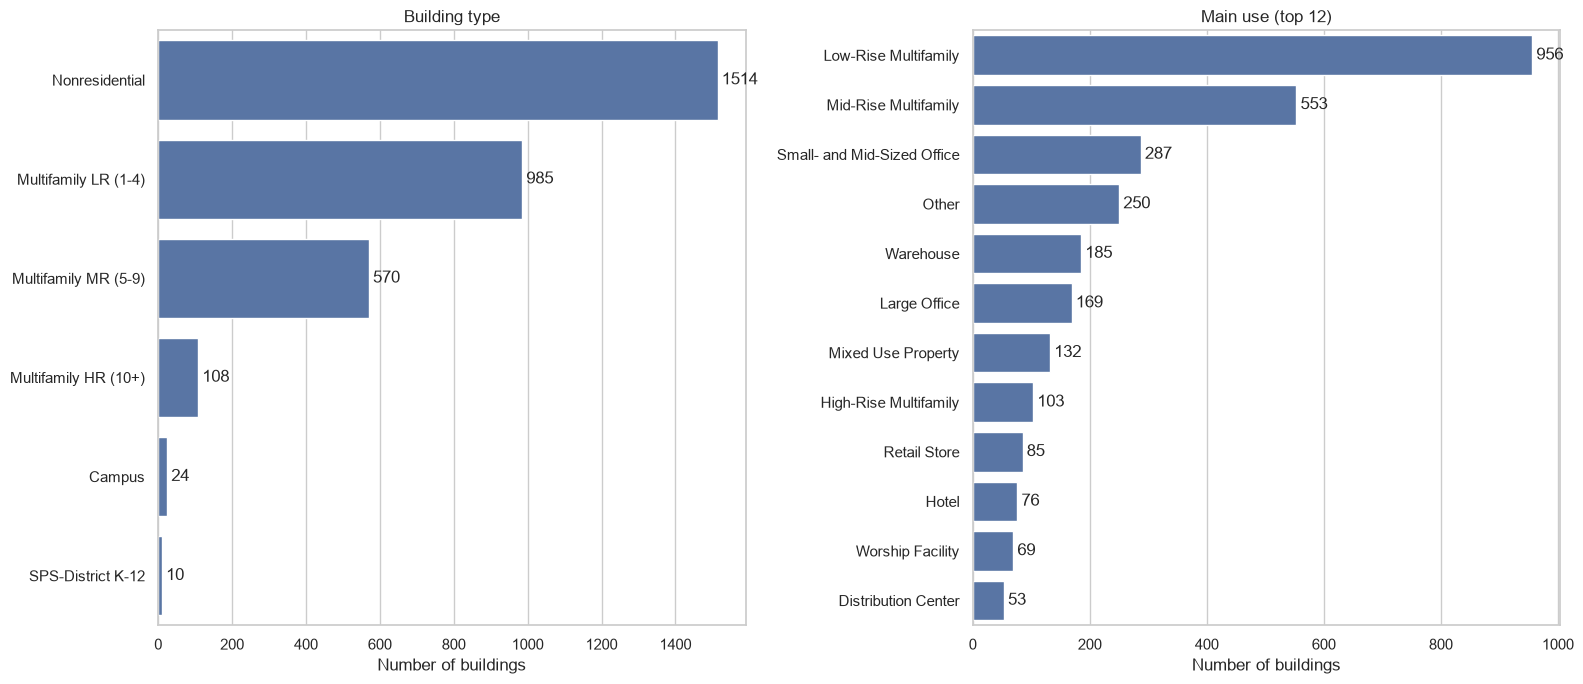

In [38]:
#number of buildings per type and per main use
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.countplot(data=df_clean, y="building_type", order=df_clean["building_type"].value_counts().index, ax=axes[0])
axes[0].bar_label(axes[0].containers[0], padding=3)
axes[0].set_title("Building type")
axes[0].set_xlabel("Number of buildings")
axes[0].set_ylabel("")

top_types = df_clean["primary_property_type"].value_counts().head(12).index
sns.countplot(data=df_clean, y="primary_property_type", order=top_types, ax=axes[1])
axes[1].bar_label(axes[1].containers[0], padding=3)
axes[1].set_title("Main use (top 12)")
axes[1].set_xlabel("Number of buildings")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig(FIG_DIR / "04_building_types.png", dpi=150, bbox_inches="tight")
plt.show()

About half of the buildings are housing, the rest mostly nonresidential. After housing, the most common are offices and warehouses. Some groups are really small (high-rises, campuses), **so a few weird buildings can change their results a lot.**

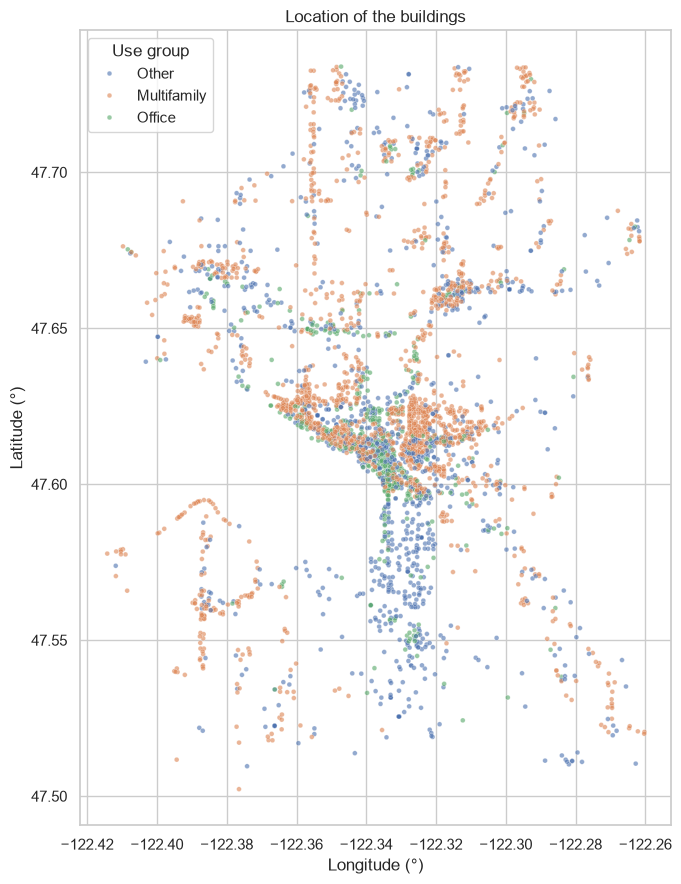

In [39]:
#map of the buildings
fig, ax = plt.subplots(figsize=(7, 9))
sns.scatterplot(data=df_clean, x="longitude", y="latitude", hue="use_group", s=12, alpha=0.6, ax=ax)
ax.legend(title="Use group")
ax.set_title("Location of the buildings")
ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_map.png", dpi=150, bbox_inches="tight")
plt.show()

Offices are all downtown, industry and warehouses in the south, housing everywhere. So if we compared neighborhoods, downtown would look worse just because it's full of offices.

## 2.4 Correlation

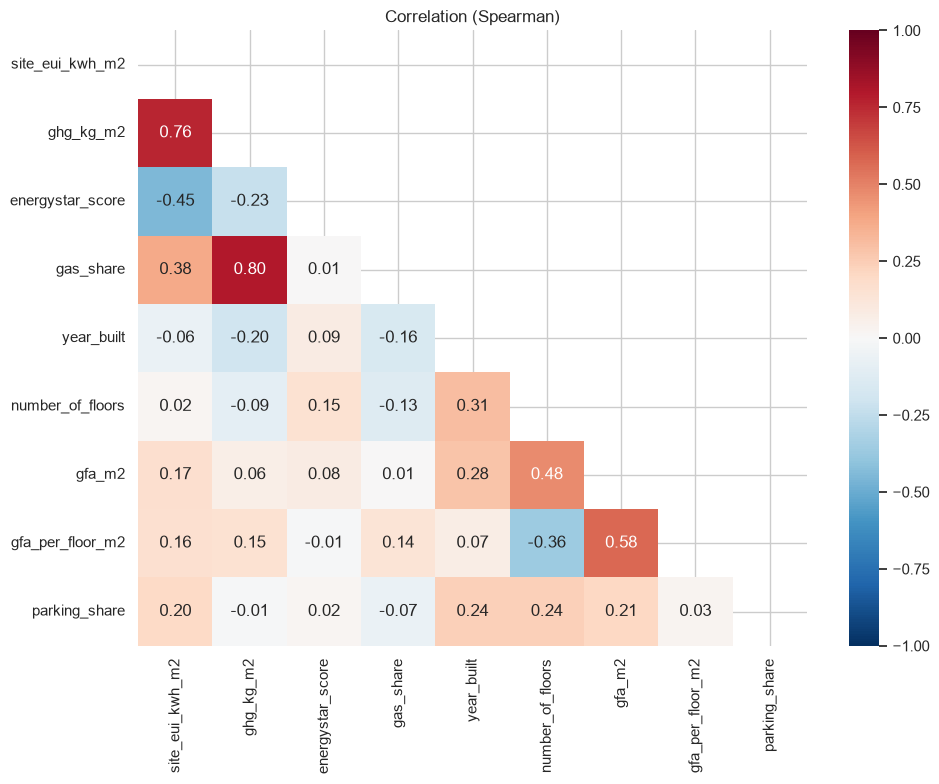

site_eui_kwh_m2     1.00
ghg_kg_m2           0.76
gas_share           0.38
parking_share       0.20
gfa_m2              0.17
gfa_per_floor_m2    0.16
number_of_floors    0.02
year_built         -0.06
energystar_score   -0.45
Name: site_eui_kwh_m2, dtype: float64

In [40]:
corr_columns = ["site_eui_kwh_m2", "ghg_kg_m2", "energystar_score", "gas_share", "year_built",
                "number_of_floors", "gfa_m2", "gfa_per_floor_m2", "parking_share"]
corr = df_clean[corr_columns].corr(method="spearman")

#hide upper half
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation (Spearman)")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

corr["site_eui_kwh_m2"].sort_values(ascending=False)

<span style="color:#b2182b">**Red**</span> = go up together, <span style="color:#2166ac">**blue**</span> = one goes up the other goes down, **white** = no relation. 

Energy per m2 goes with emissions and with gas, but size, floors and age alone barely matter. The strongest one is emissions vs gas (0.80): it's the gas that makes the CO2, not how much energy you use. The use of the building isn't in here because it's not a number, and that's the one that matters most (Q1).

Correlation is not causation. Also careful if we build a model: emissions, ENERGY STAR, gas share and the energy columns all come from the same energy bills, so we can't use them to predict the energy (leakage).

## 2.5 Q1: which types of buildings use the most energy per m2?

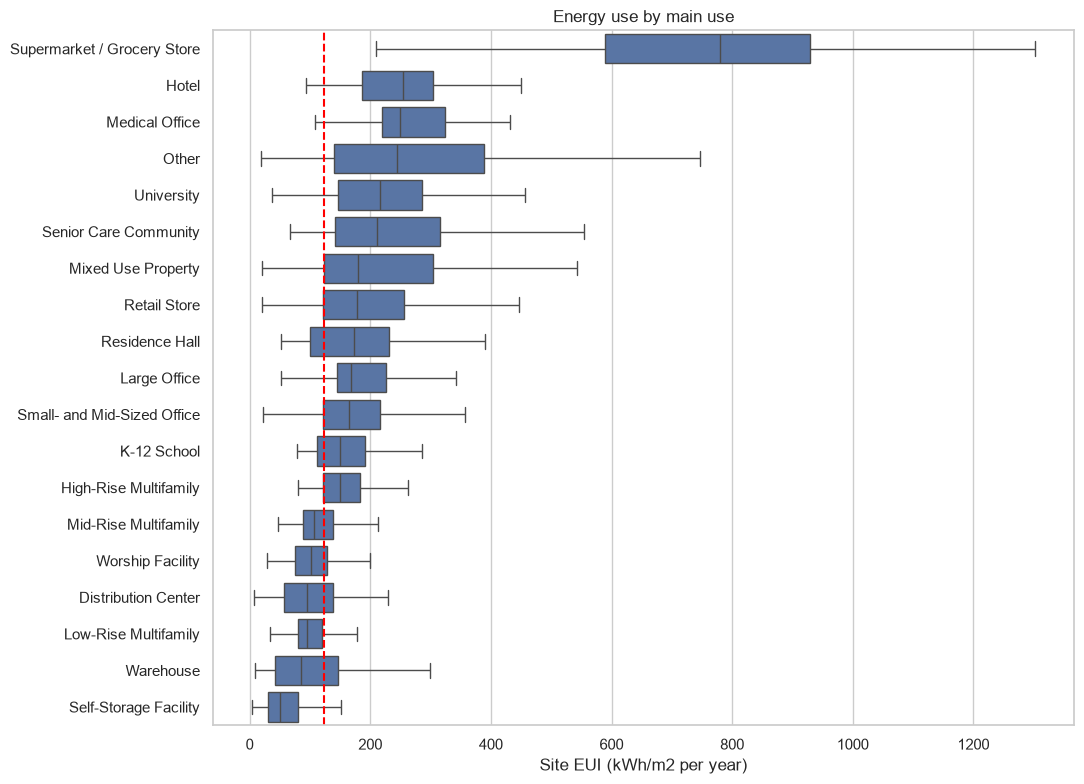

,count,median
primary_property_type,,
Supermarket / Grocery Store,40,779.19
Hotel,76,253.79
Medical Office,39,248.90
Other,250,243.85
University,25,216.41
Senior Care Community,44,210.41
Mixed Use Property,132,180.44
Retail Store,85,177.92
Residence Hall,23,172.87


In [41]:
#uses with at least 20 buildings
type_counts = df_clean["primary_property_type"].value_counts()
common_types = type_counts[type_counts >= 20].index
df_types = df_clean[df_clean["primary_property_type"].isin(common_types)]

#order from highest to lowest median
type_order = df_types.groupby("primary_property_type")["site_eui_kwh_m2"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(11, 8))
sns.boxplot(data=df_types, x="site_eui_kwh_m2", y="primary_property_type", order=type_order,
            showfliers=False, ax=ax)
ax.axvline(df_clean["site_eui_kwh_m2"].median(), color="red", linestyle="--")
ax.set_title("Energy use by main use")
ax.set_xlabel("Site EUI (kWh/m2 per year)")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_eui_by_use.png", dpi=150, bbox_inches="tight")
plt.show()

df_types.groupby("primary_property_type")["site_eui_kwh_m2"].agg(["count", "median"]).sort_values("median", ascending=False)

The use of the building is what changes the energy the most. Supermarkets are way above everything else (fridges running all day), then hotels, medical offices and universities (open 24h). Offices are a bit above the median, housing and warehouses at the bottom. "Other" is all over the place because it mixes very different buildings, data centers included.

## 2.6 Q2: do older buildings use more energy?
Split by use, since use changes energy a lot.

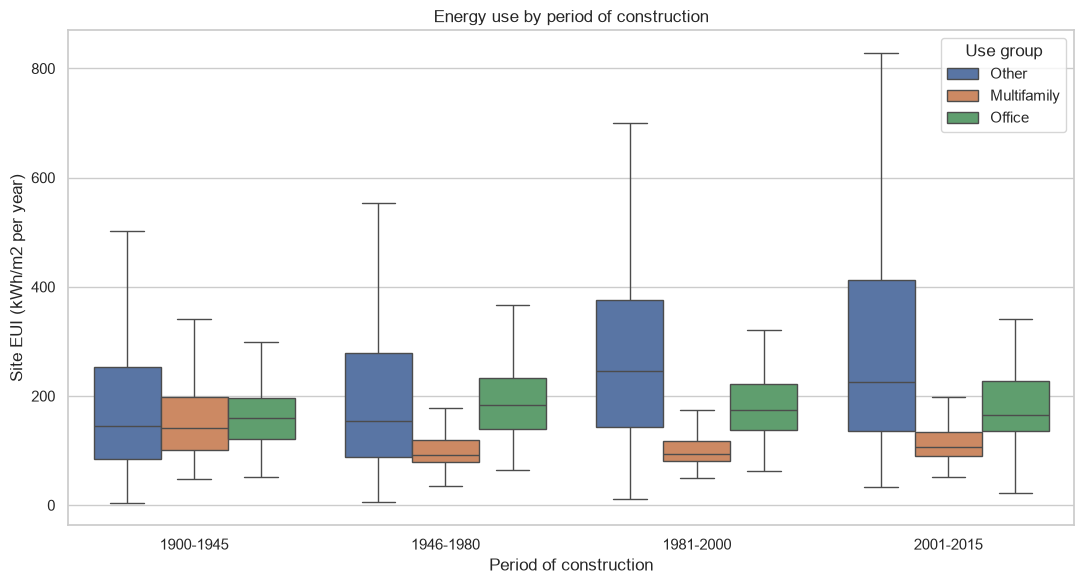

use_group,Multifamily,Office,Other
period,,,
1900-1945,142.27,158.99,144.32
1946-1980,92.75,183.76,154.89
1981-2000,94.01,174.45,246.22
2001-2015,106.94,164.35,225.71


In [42]:
#periods of construction
df_clean["period"] = pd.cut(
    df_clean["year_built"],
    bins=[1899, 1945, 1980, 2000, 2015],
    labels=["1900-1945", "1946-1980", "1981-2000", "2001-2015"],
)

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=df_clean, x="period", y="site_eui_kwh_m2", hue="use_group", showfliers=False, ax=ax)
ax.set_title("Energy use by period of construction")
ax.set_xlabel("Period of construction")
ax.set_ylabel("Site EUI (kWh/m2 per year)")
ax.legend(title="Use group")
plt.tight_layout()
plt.savefig(FIG_DIR / "08_eui_by_period.png", dpi=150, bbox_inches="tight")
plt.show()

df_clean.pivot_table(index="period", columns="use_group", values="site_eui_kwh_m2", aggfunc="median", observed=True)

In [43]:
#how many buildings in each group
pd.crosstab(df_clean["period"], df_clean["use_group"])

use_group,Multifamily,Office,Other
period,,,
1900-1945,308,146,314
1946-1980,452,124,453
1981-2000,480,117,190
2001-2015,422,69,136


We split by use because use changes energy a lot as can be seen by the answer to Q1. 

Old housing (before 1946) clearly uses more than newer housing, probably no insulation and old heating back then. 
Offices don't really change with age, mostly because they get renovated more often.
"Other" mixes too many different buildings to say anything. 
We don't know which buildings got renovated, which could change a lot.

## 2.7 Q3: amount of energy or type of energy?

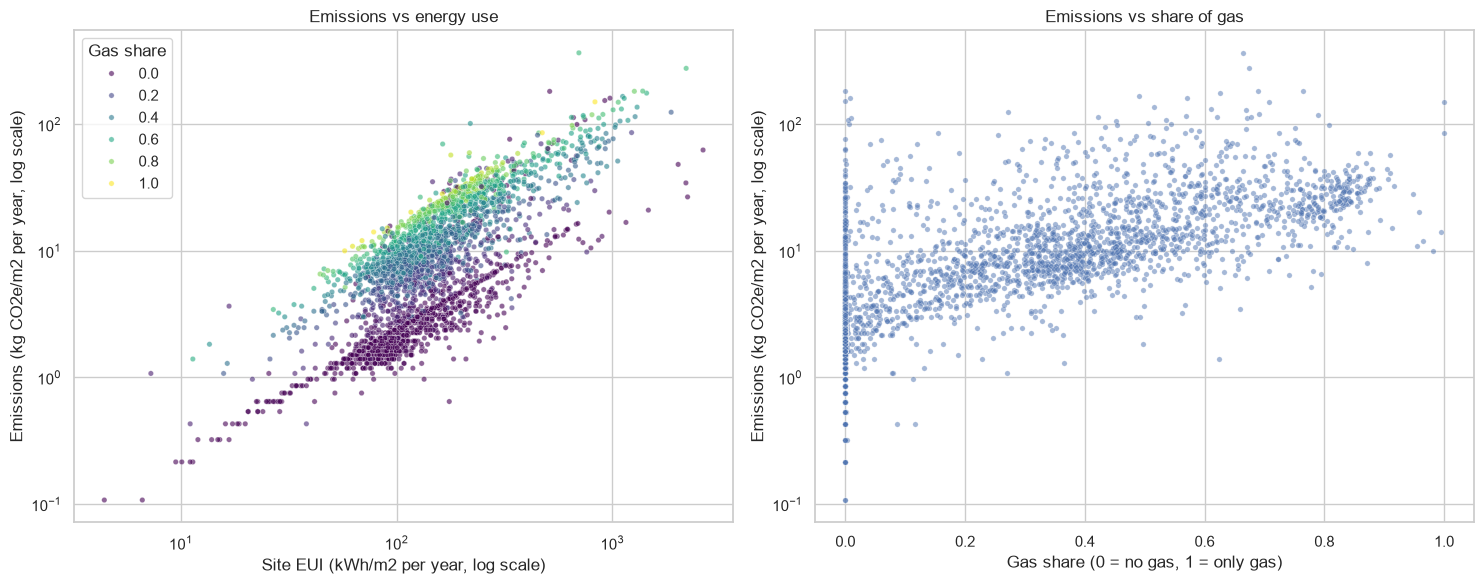

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

#emissions vs energy use, coloured by gas share
sns.scatterplot(data=df_clean, x="site_eui_kwh_m2", y="ghg_kg_m2", hue="gas_share", palette="viridis",
                s=15, alpha=0.6, ax=axes[0])
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title("Emissions vs energy use")
axes[0].set_xlabel("Site EUI (kWh/m2 per year, log scale)")
axes[0].set_ylabel("Emissions (kg CO2e/m2 per year, log scale)")
axes[0].legend(title="Gas share")

#emissions vs gas share
sns.scatterplot(data=df_clean, x="gas_share", y="ghg_kg_m2", s=15, alpha=0.5, ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Emissions vs share of gas")
axes[1].set_xlabel("Gas share (0 = no gas, 1 = only gas)")
axes[1].set_ylabel("Emissions (kg CO2e/m2 per year, log scale)")

plt.tight_layout()
plt.savefig(FIG_DIR / "09_gas_vs_emissions.png", dpi=150, bbox_inches="tight")
plt.show()

In [45]:
#3 groups of buildings by gas share
df_clean["gas_group"] = pd.cut(df_clean["gas_share"], bins=[-0.01, 0, 0.5, 1],
                               labels=["No gas", "Up to 50% gas", "More than 50% gas"])

df_clean.groupby("gas_group", observed=True)[["site_eui_kwh_m2", "ghg_kg_m2"]].median()

,site_eui_kwh_m2,ghg_kg_m2
gas_group,,
No gas,93.22,2.05
Up to 50% gas,135.65,8.18
More than 50% gas,182.34,23.14


In [46]:
#kg co2 per kwh
df_clean["kg_co2_per_kwh"] = df_clean["ghg_kg_m2"] / df_clean["site_eui_kwh_m2"]
df_clean.groupby("gas_group", observed=True)["kg_co2_per_kwh"].median()

gas_group
No gas              0.02
Up to 50% gas       0.06
More than 50% gas   0.13
Name: kg_co2_per_kwh, dtype: float64

Left plot: for the same energy use, buildings with gas (green/yellow) are way higher than the ones without gas (purple). Gas buildings use about 2x more energy but emit about 11x more CO2. Seattle's electricity is mostly hydro so it's super clean, while gas is burned in the building. So the type of energy matters more than the amount, switching from gas to electric would cut a lot of CO2. Only works because the electricity here is clean though.

## 2.8 Q4: do tall residential buildings use more energy?

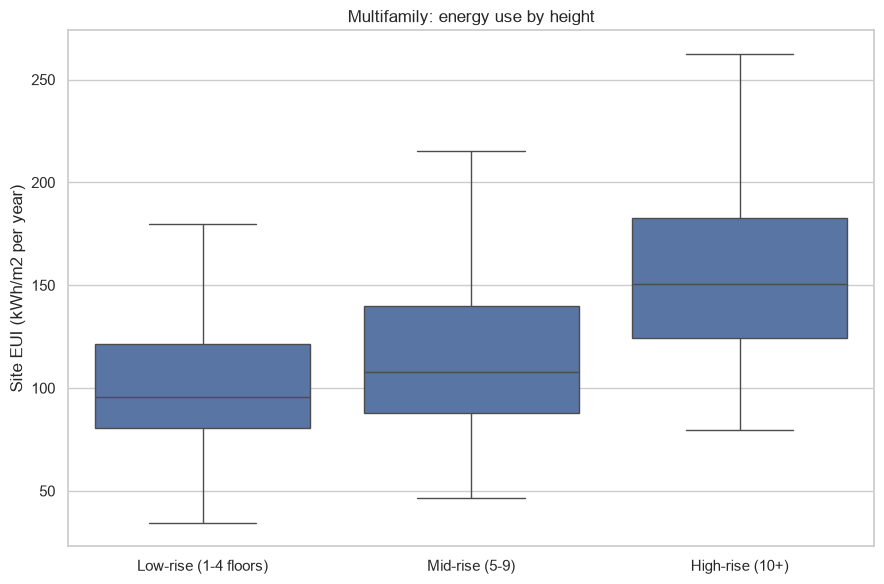

,site_eui_kwh_m2,gas_share,year_built,gfa_m2
building_type,,,,
Multifamily LR (1-4),95.58,0.00,"1,978.00","2,916.18"
Multifamily MR (5-9),107.89,0.27,"1,999.00","5,508.18"
Multifamily HR (10+),150.47,0.31,"1,982.00","16,042.19"


In [47]:
#only multifamily buildings
df_multi = df_clean[df_clean["use_group"] == "Multifamily"]
height_order = ["Multifamily LR (1-4)", "Multifamily MR (5-9)", "Multifamily HR (10+)"]

fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=df_multi, x="building_type", y="site_eui_kwh_m2", order=height_order, showfliers=False, ax=ax)
ax.set_title("Multifamily: energy use by height")
ax.set_xlabel("")
ax.set_xticks(range(3), ["Low-rise (1-4 floors)", "Mid-rise (5-9)", "High-rise (10+)"])
ax.set_ylabel("Site EUI (kWh/m2 per year)")
plt.tight_layout()
plt.savefig(FIG_DIR / "10_multifamily_height.png", dpi=150, bbox_inches="tight")
plt.show()

df_multi.groupby("building_type")[["site_eui_kwh_m2", "gas_share", "year_built", "gfa_m2"]].median().loc[height_order]

Same use (housing), only the height changes, so it's a fair comparison. Taller buildings use clearly more energy per m2, probably elevators, corridors and ventilation running all the time. But high-rises also have gas more often and are way bigger, so it's not only the height. They're not newer though, so age isn't the reason.

# 3. Conclusions

### What we found
- The data was pretty clean already, we mostly had to take out the 165 buildings the city doesn't trust and fix some spelling and impossible values. In the end we have 3,211 buildings.
- What a building is used for matters the most. Supermarkets use like 16 times more energy per m2 than self storage, and offices use more than housing.
- Age only makes a difference for housing: the old ones (before 1946) use clearly more. For offices it doesn't really change.
- For CO2 it's more about gas than about how much energy you use. Gas buildings use about 2x more energy but emit about 11x more, because Seattle's electricity is mostly hydro.
- Taller housing uses more energy per m2 (high-rise about 57% more than low-rise), but they also use more gas and are much bigger, so it's not only the height.

### Limitations
- Only big buildings, only Seattle and only 2016, so we can't really say this for other cities (especially the gas part, Seattle has very clean electricity).
- The owners report the data themselves, so there can still be mistakes.
- We don't know anything about renovations, insulation or heating systems, which probably matter a lot.
- Some groups are small (like the high-rises or the new offices), so those results are less sure.

### Ready for modelling
- The thing to predict would be `site_eui_kwh_m2`, probably on a log scale since it's so skewed.
- We can't use the energy columns, `gas_share`, the emissions or `energystar_score` as inputs, they all come from the same energy bills (leakage).
- The missing values stay as NaN for now, they'd need to be filled using only the training data.